In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')
#/content/gdrive/My Drive/ColabIP26/Images/

Mounted at /content/gdrive


In [18]:
def threshold_update(img, binImg,T):
  sum1 =np.int32(0)
  sum2 =np.int32(0)
  count1 =1
  count2 =1
  for i in range(img.shape[0]):
    for j in range(img.shape[1]):
      if binImg[i][j] == 0:
        sum1 = sum1 + img[i][j]
        count1 = count1 + 1
      else:
        sum2 = sum2 + img[i][j]
        count2 = count2 + 1
  avg1 = sum1 /count1
  avg2 = sum2 /count2
  T2 = np.int32(avg1 + avg2)/2
  return T2


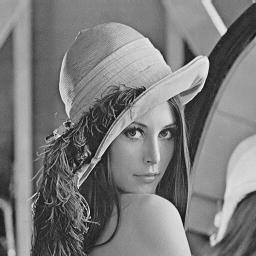

In [36]:
img = cv2.imread('/content/gdrive/My Drive/colabIP_26/images/lena256.jpg')
#img = cv2.imread('/content/gdrive/My Drive/colabIP_26/images/milkdrop.bmp')
#img = cv2.imread('/content/gdrive/My Drive/colabIP_26/images/cell-bright.bmp')
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gimg1 = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

cv2_imshow(gimg1)

In [31]:
T1 = 128
T2 =0
binImg = np.zeros(gimg1.shape, dtype=np.uint8)


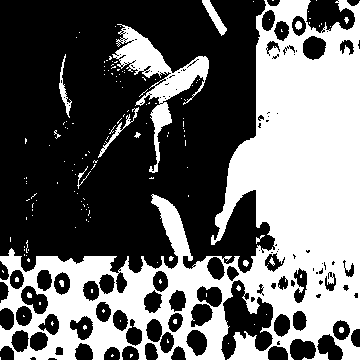

In [37]:
for i in range(gimg1.shape[0]):
  for j in range(gimg1.shape[1]):
    if gimg1[i][j] > T1:
      binImg[i][j] = 255
    else:
      binImg[i][j] = 0
cv2_imshow(binImg)

In [38]:
while True:
  T2 = threshold_update(gimg1, binImg,T1)
  if(np.abs(T1-T2) < 1):
    for i in range(gimg1.shape[0]):
      for j in range(gimg1.shape[1]):
        if gimg1[i][j] > T2:
          binImg[i][j] = 255
        else:
          binImg[i][j] = 0
    break
  else:
    T1 = T2
    for i in range(gimg1.shape[0]):
      for j in range(gimg1.shape[1]):
        if gimg1[i][j] > T1:
          binImg[i][j] = 255
        else:
          binImg[i][j] = 0


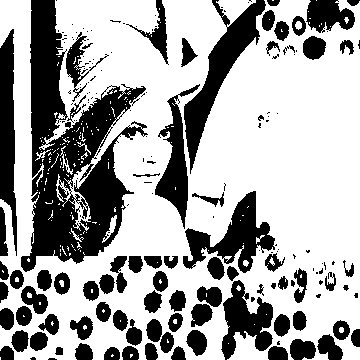

116.5


In [40]:
cv2_imshow(binImg)
print(T1)

116.0


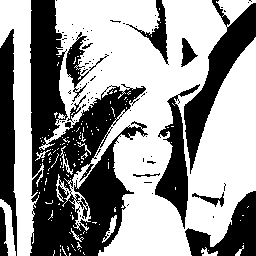

In [39]:
t, otsu =cv2.threshold(gimg1, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(t)
cv2_imshow(otsu)